In [11]:
#EDA ideas borrowed from https://www.kaggle.com/code/egorandreasyan/baseline-eda-stellar-class
import os
import math
from pathlib import Path
import pickle
import random
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    log_loss,
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    f1_score,
    precision_score,
    roc_curve
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.cluster import KMeans
from itertools import combinations
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    HistGradientBoostingClassifier, 
    RandomForestClassifier
)
from sklearn.pipeline import Pipeline
# from catboost import CatBoostClassifier
# from xgboost import XGBClassifier
# import lightgbm as lgb
# from lightgbm import LGBMClassifier
# from scipy.optimize import differential_evolution, minimize
# from scipy.special import softmax
from itertools import combinations
from collections import Counter
import seaborn as sns
from tqdm import tqdm
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("train.csv")
print("Number of rows:", df.shape[0])
print("Number of unique objects in 'class' column:", df['class'].unique())
print(df.columns)

Number of rows: 577347
Number of unique objects in 'class' column: ['GALAXY' 'QSO' 'STAR']
Index(['id', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'redshift',
       'spectral_type', 'galaxy_population', 'class'],
      dtype='object')


In [8]:
for obj in ['spectral_type','galaxy_population','class']:
    print(f"Unique objects in '{obj}' column:", df[obj].unique())

Unique objects in 'spectral_type' column: ['M' 'O/B' 'G/K' 'A/F']
Unique objects in 'galaxy_population' column: ['Red_Sequence' 'Blue_Cloud']
Unique objects in 'class' column: ['GALAXY' 'QSO' 'STAR']


In [27]:
def plot_smart_pie_charts(df: pd.DataFrame) -> list:
    sns.set_theme(style="whitegrid", palette="pastel")
    obj_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    n_features = len(obj_cols)
    if n_features == 0:
        return
    if n_features <= 3:
        cols_in_row = n_features
    elif n_features == 4:
        cols_in_row = 2
    else:
        cols_in_row = 3 if n_features < 10 else 4
    rows = math.ceil(n_features / cols_in_row)
    fig, axes = plt.subplots(rows, cols_in_row,
                             figsize=(cols_in_row * 5, rows * 5),
                             squeeze=False)
    axes = axes.flatten()
    for i, col in enumerate(obj_cols):
        ax = axes[i]
        counts = df[col].value_counts()
        limit = 8
        if len(counts) > limit:
            top = counts.iloc[:limit-1]
            others = pd.Series({'Others': counts.iloc[limit-1:].sum()})
            plot_data = pd.concat([top, others])
        else:
            plot_data = counts
        plot_data = plot_data.sort_index(ascending=False)
        ax.pie(plot_data,
               labels=plot_data.index,
               autopct='%1.1f%%',
               startangle=140,
               pctdistance=0.85,
               colors=sns.color_palette("hls", len(plot_data)),
               wedgeprops={'width': 0.5, 'edgecolor': 'w', 'linewidth': 2})
        ax.set_title(f"{col}", fontsize=14, fontweight='bold', pad=20)
    for j in range(n_features, len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()
    return obj_cols




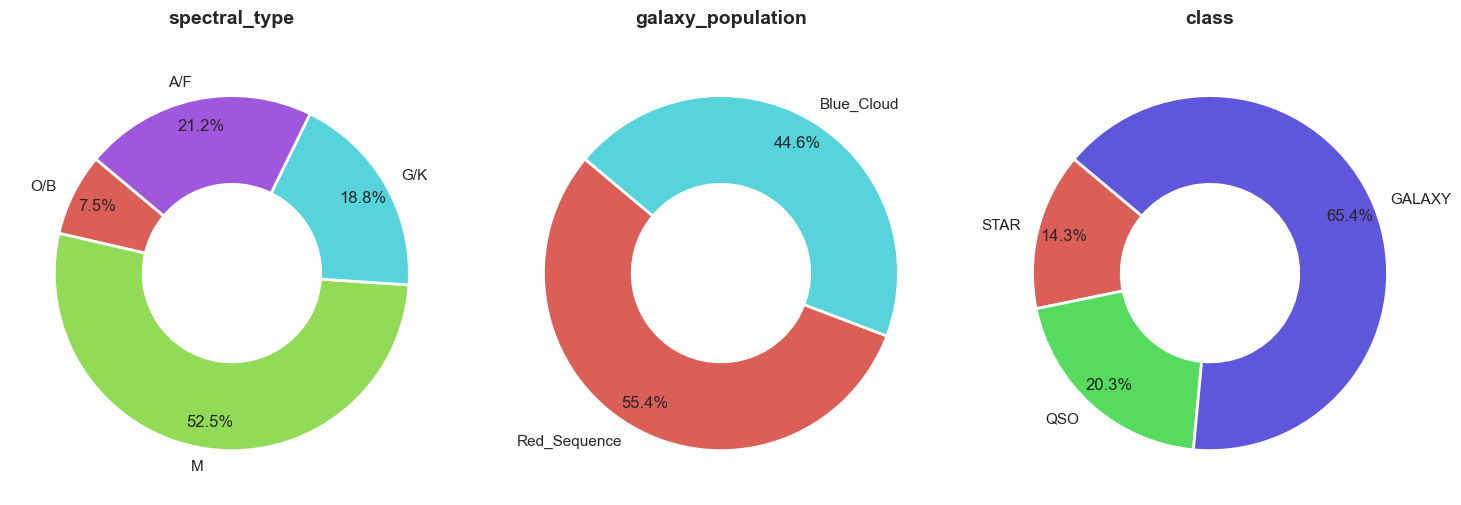

In [28]:
cat_cols = plot_smart_pie_charts(df)

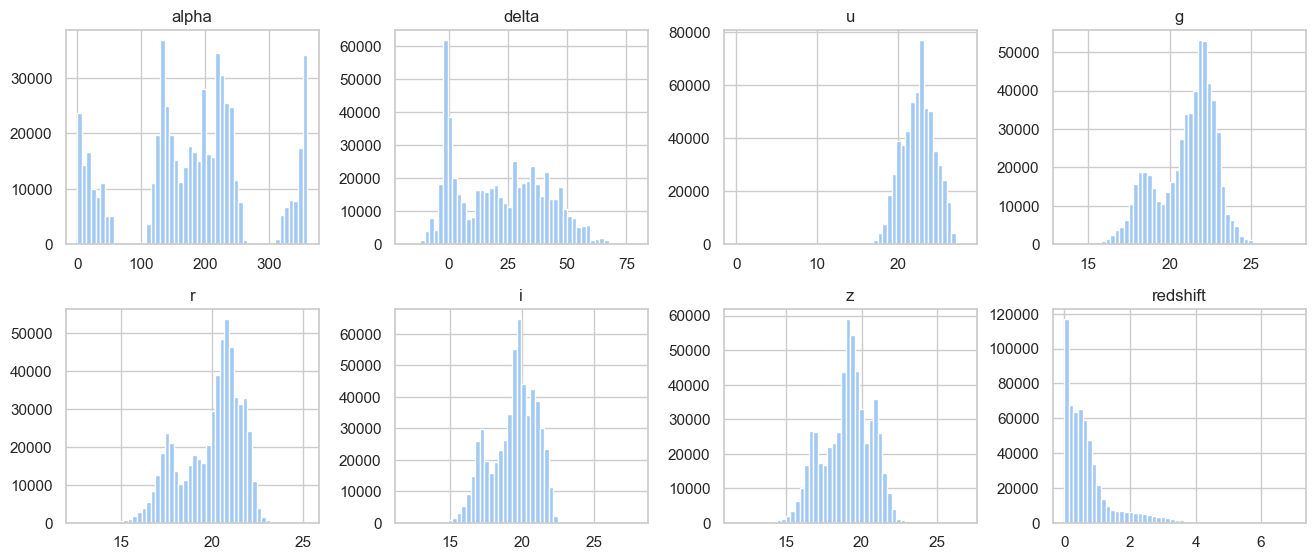

In [29]:
data = df.copy()
data = data.drop(columns=['id'])
n = data.select_dtypes('number').shape[1]
data.hist(figsize=(min(4, n) * 4, ((n + 3) // 4) * 3.2), bins=50, layout=(-1, 4));

Classification: GALAXY


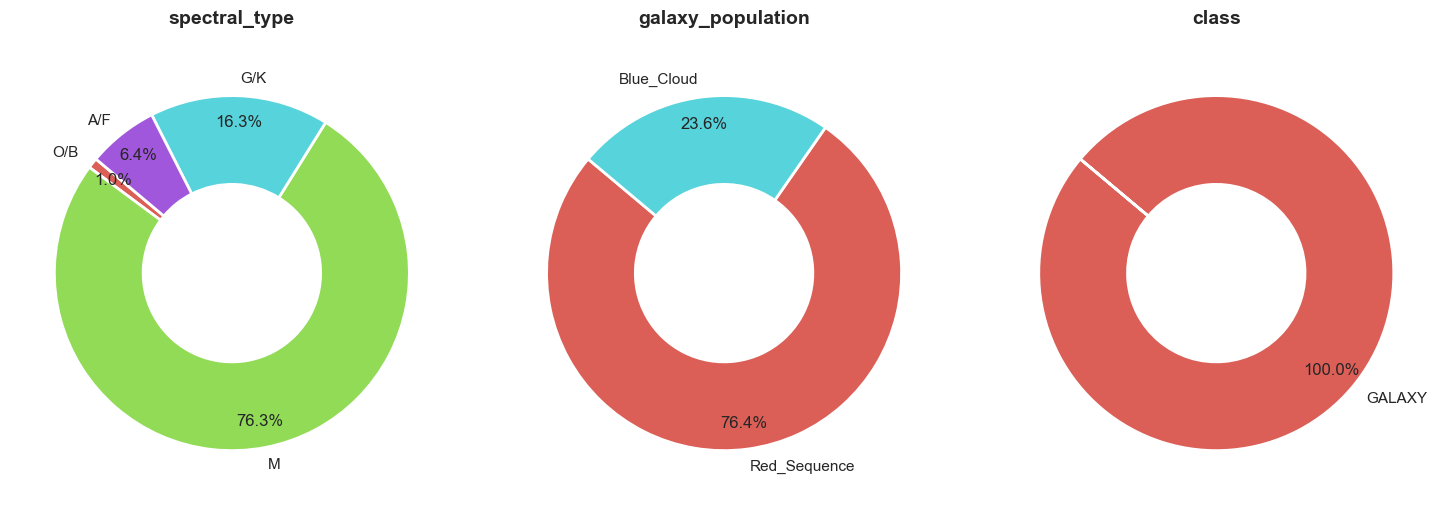

Classification: QSO


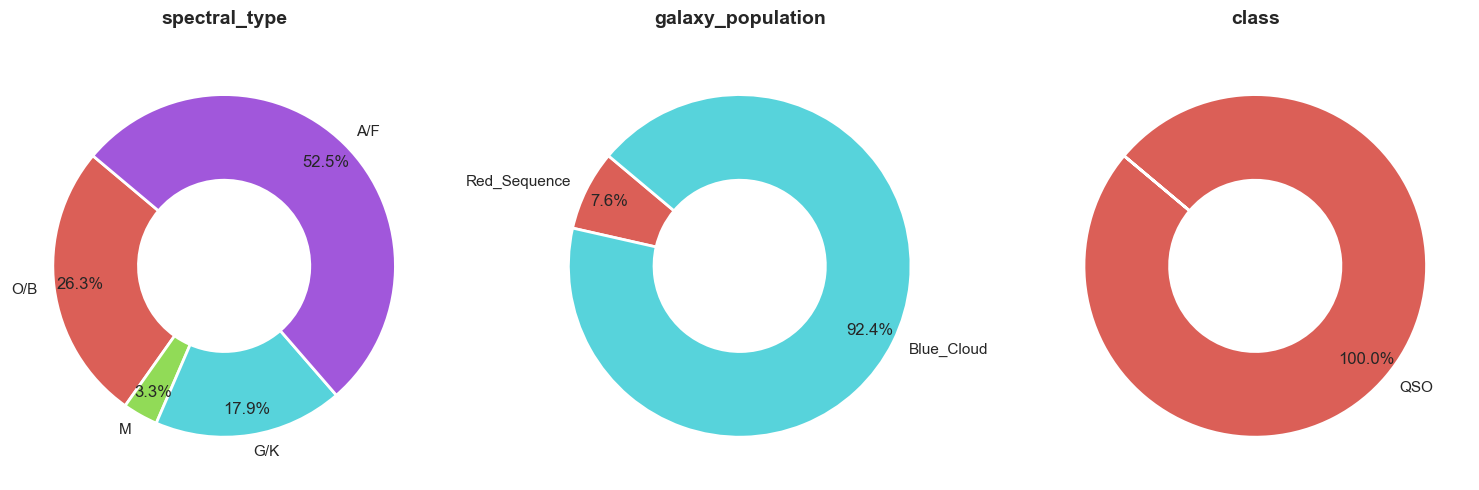

Classification: STAR


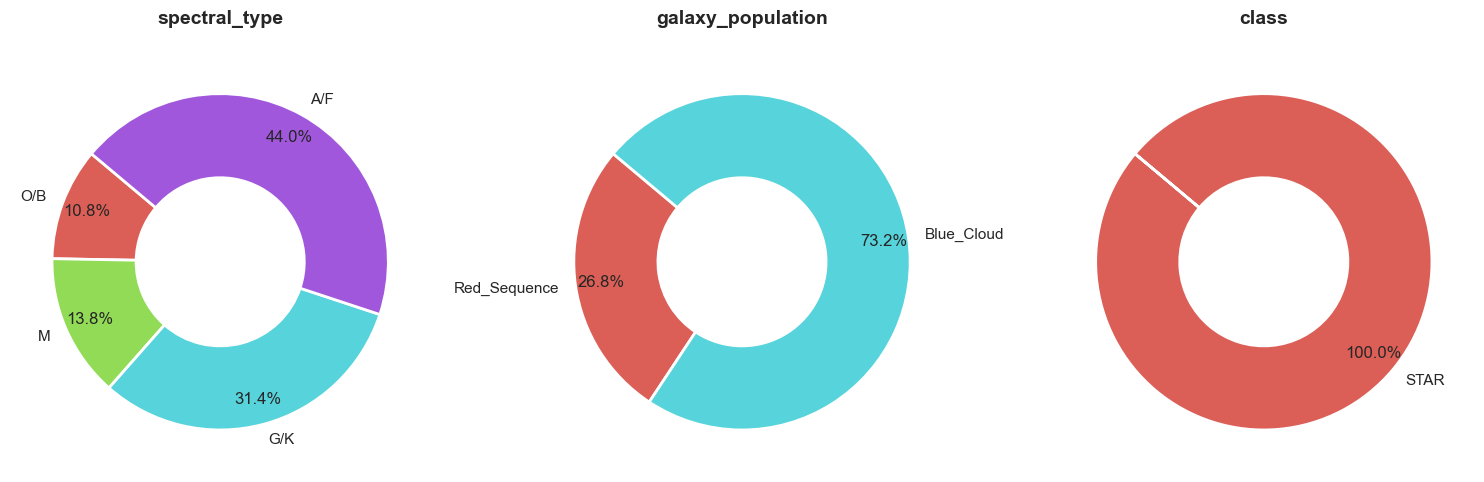

In [30]:
#now, do this for each class type
#categoricals
for classification in df['class'].unique():
    df_filtered = df[df['class'] == classification].copy()
    df_filtered = df_filtered.drop(columns=['id'])
    print(f'Classification: {classification}')
    plot_smart_pie_charts(df_filtered)


Classification: GALAXY
Classification: QSO
Classification: STAR


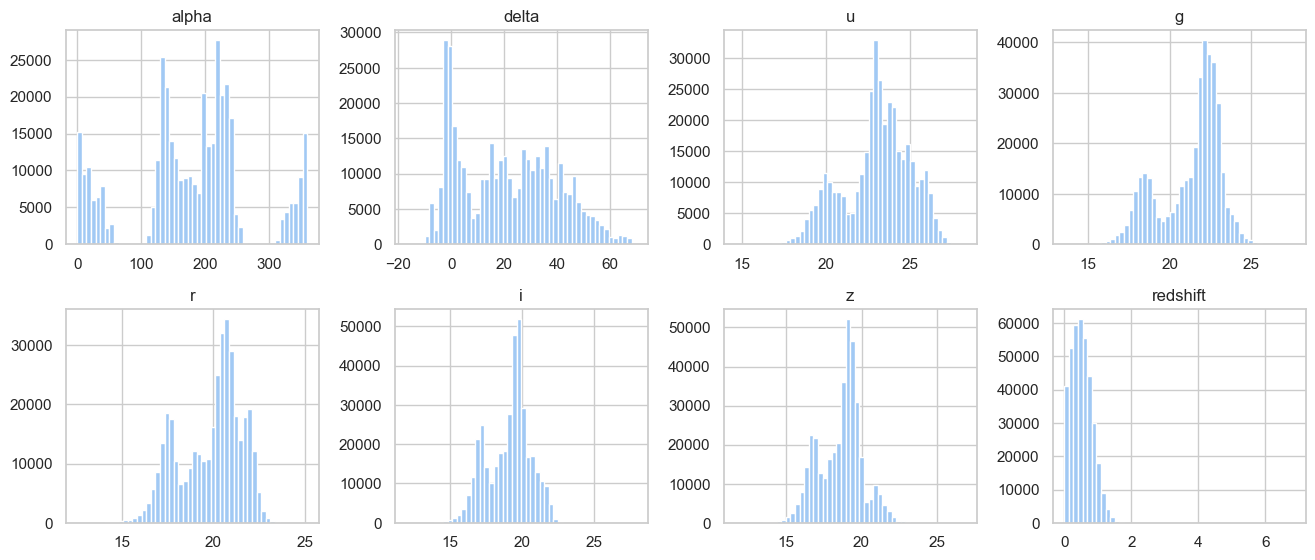

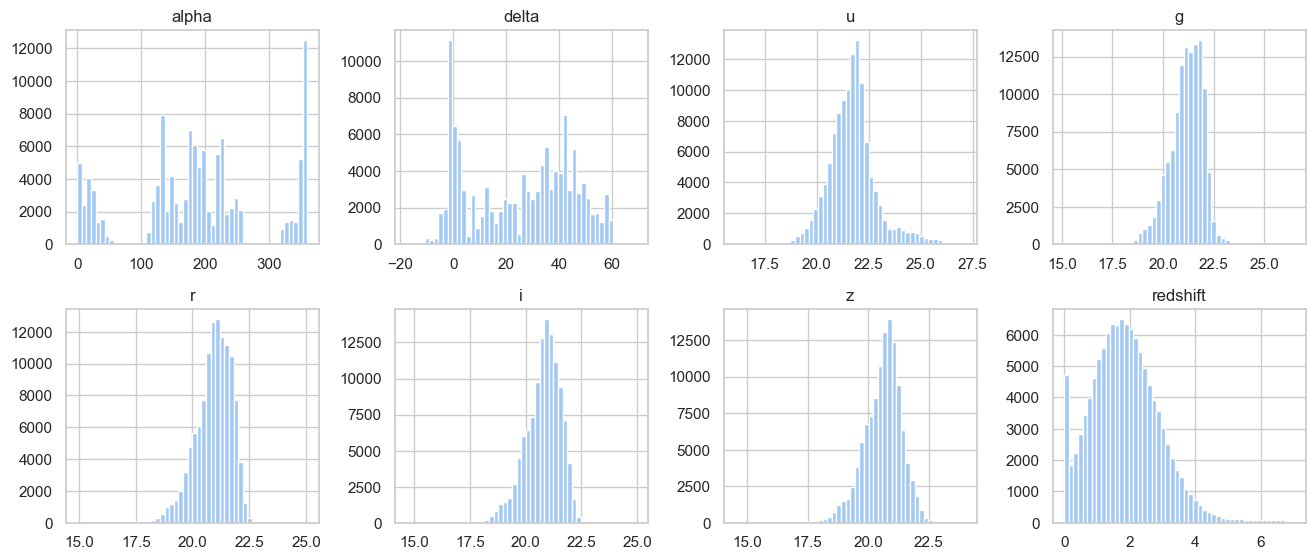

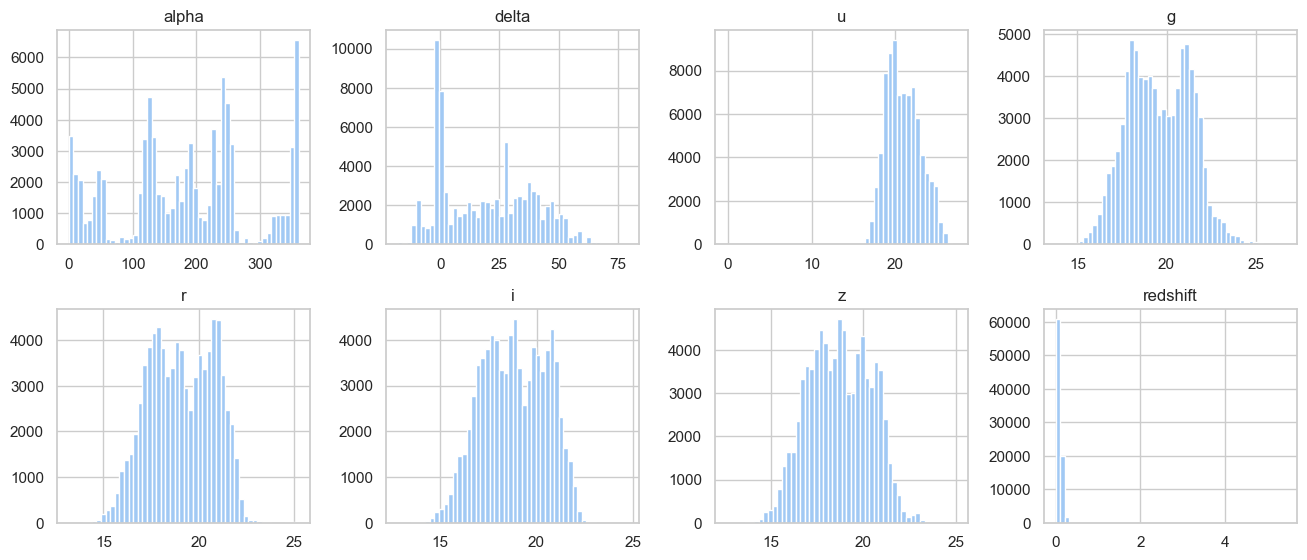

In [22]:
#and for numerics
for classification in df['class'].unique():
    df_filtered = df[df['class'] == classification].copy()
    df_filtered = df_filtered.drop(columns=['id'])
    print(f'Classification: {classification}')
    # plot_smart_pie_charts(df_filtered)
    data = df_filtered
    n = data.select_dtypes('number').shape[1]
    data.hist(figsize=(min(4, n) * 4, ((n + 3) // 4) * 3.2), bins=50, layout=(-1, 4));
